# Arabic Audio Dataset Exploration and Preparation

## Project Overview

This notebook explores and prepares an Arabic audio dataset for the graduation project, which aims to recognize spoken Arabic letters and convert them into Braille output.

The main objectives are to:
- Explore the dataset and its class distribution.
- Inspect audio properties such as duration, sample rate, and number of channels.
- Check audio files for reading errors and potential silence.
- Create a metadata file containing audio paths and labels.
- Split the dataset into training, validation, and test sets.
- Visualize an example audio waveform.

In [2]:
from pathlib import Path

DATA_DIR = Path("../data/raw/Cleaned Audio Dataset")

print("Dataset exists:", DATA_DIR.exists())
print("Dataset path:", DATA_DIR.resolve())

Dataset exists: True
Dataset path: C:\Users\home\Desktop\braile\data\raw\Cleaned Audio Dataset


In [ ]:

from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

files_per_letter = Counter()

for folder in DATA_DIR.iterdir():   # بنشوف عندنا كام ملف في كل حرف
    if folder.is_dir():
        files_per_letter[folder.name] = sum(
            1 for file in folder.iterdir()
            if file.is_file() and file.suffix.lower() == ".wav"
        )

counts_df = pd.DataFrame(
    files_per_letter.items(),
    columns=["Letter", "Number_of_Audio_Files"]
).sort_values("Letter")

print("Number of letters:", len(counts_df))
print("Total audio files:", counts_df["Number_of_Audio_Files"].sum())

display(counts_df)


Number of letters: 28
Total audio files: 1435


,Letter,Number_of_Audio_Files
0,Ain,50
1,Alif,78
2,Ba,56
3,Dad,42
4,Dal,43
5,Fa,52
6,Ghain,38
7,Ha,52
8,Ha2,59
9,Jeem,49


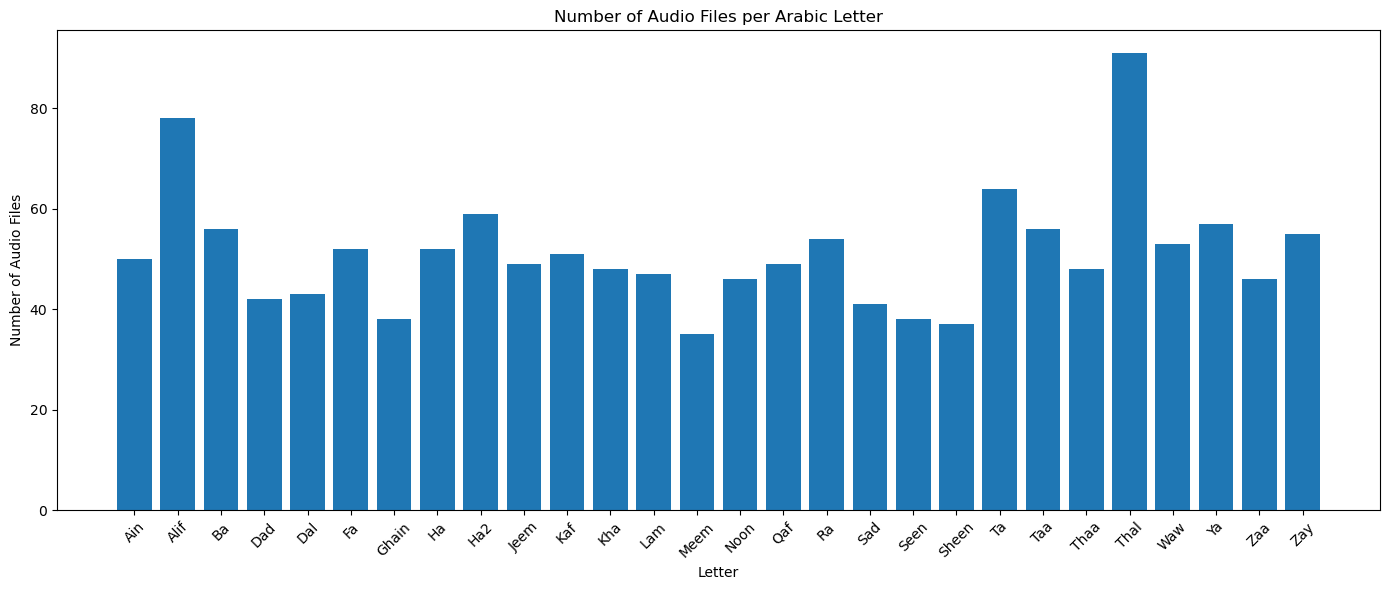

In [ ]:
  # بنرسم توزيع الداتا عشان نشوف كل حرف عنده كام عينة
plt.figure(figsize=(14, 6))

plt.bar(
    counts_df["Letter"],
    counts_df["Number_of_Audio_Files"]
)

plt.title("Number of Audio Files per Arabic Letter")
plt.xlabel("Letter")
plt.ylabel("Number of Audio Files")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
#  no.of channels بنشوف مدة الصوت والـ sample rate و


import wave
from statistics import mean
from collections import Counter

durations = []
sample_rates = Counter()
channels_count = Counter()
errors = []

for file_path in DATA_DIR.rglob("*.wav"):
    try:
        with wave.open(str(file_path), "rb") as audio:
            sample_rate = audio.getframerate()
            channels = audio.getnchannels()
            frames = audio.getnframes()

            duration = frames / sample_rate

            durations.append(duration)
            sample_rates[sample_rate] += 1
            channels_count[channels] += 1

    except Exception as error:
        errors.append((file_path, str(error)))

print("Readable audio files:", len(durations))
print("Files with errors:", len(errors))

if durations:
    print(f"Shortest duration: {min(durations):.2f} seconds")
    print(f"Longest duration: {max(durations):.2f} seconds")
    print(f"Average duration: {mean(durations):.2f} seconds")

print("\nSample Rates:")
for rate, count in sorted(sample_rates.items()):
    print(f"{rate} Hz: {count} files")

print("\nChannels:")
for channels, count in sorted(channels_count.items()):
    print(f"{channels} channel(s): {count} files")


Readable audio files: 1435
Files with errors: 0
Shortest duration: 1.00 seconds
Longest duration: 1.00 seconds
Average duration: 1.00 seconds

Sample Rates:
16000 Hz: 1435 files

Channels:
1 channel(s): 1435 files


In [ ]:
# بنتأكد إن الملفات بتتقرأ ومفيش مشاكل واضحة فيها
from IPython.display import Audio, display
import random

# اختيار تسجيل عشوائي من فولدر Ain
ain_files = list((DATA_DIR / "Ain").glob("*.wav"))
sample_file = random.choice(ain_files)

print("File:", sample_file.name)
print("Label from folder:", sample_file.parent.name)

display(Audio(filename=str(sample_file)))



File: 17_Ain_15.wav
Label from folder: Ain


In [7]:

from IPython.display import Audio, display
import random

letters_to_check = ["Alif", "Ba", "Thal"]

for letter in letters_to_check:
    files = list((DATA_DIR / letter).glob("*.wav"))
    sample_file = random.choice(files)

    print(f"Letter: {letter}")
    print(f"File: {sample_file.name}")
    display(Audio(filename=str(sample_file)))


Letter: Alif
File: 0_Alif_70.wav


Letter: Ba
File: 1_Ba_22.wav


Letter: Thal
File: 8_Thal_29.wav


In [ ]:

from pathlib import Path
import pandas as pd

# مكان ملفات الصوت
DATA_DIR = Path("../data/raw/Cleaned Audio Dataset")

# مكان حفظ ملف الـ metadata
OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# جمع ملفات الصوت وربط كل ملف بالـ label بتاعه
records = []

for file_path in sorted(DATA_DIR.rglob("*.wav")):
    records.append({
        "file_path": file_path.relative_to("..").as_posix(),
        "label": file_path.parent.name
    })

# تحويل البيانات إلى DataFrame
metadata = pd.DataFrame(records)

# حفظ الملف
output_file = OUTPUT_DIR / "metadata.csv"
metadata.to_csv(output_file, index=False)


print("Total audio files:", len(metadata))
print("Number of labels:", metadata["label"].nunique())
print("Duplicate rows:", metadata.duplicated().sum())
print("\nFiles per label:")
print(metadata["label"].value_counts().sort_index())
print("\nFirst 5 rows:")
display(metadata.head())

print("\nSaved to:", output_file.resolve())



Total audio files: 1435
Number of labels: 28
Duplicate rows: 0

Files per label:
label
Ain      50
Alif     78
Ba       56
Dad      42
Dal      43
Fa       52
Ghain    38
Ha       52
Ha2      59
Jeem     49
Kaf      51
Kha      48
Lam      47
Meem     35
Noon     46
Qaf      49
Ra       54
Sad      41
Seen     38
Sheen    37
Ta       64
Taa      56
Thaa     48
Thal     91
Waw      53
Ya       57
Zaa      46
Zay      55
Name: count, dtype: int64

First 5 rows:


,file_path,label
0,data/raw/Cleaned Audio Dataset/Ain/17_Ain_1.wav,Ain
1,data/raw/Cleaned Audio Dataset/Ain/17_Ain_10.wav,Ain
2,data/raw/Cleaned Audio Dataset/Ain/17_Ain_11.wav,Ain
3,data/raw/Cleaned Audio Dataset/Ain/17_Ain_12.wav,Ain
4,data/raw/Cleaned Audio Dataset/Ain/17_Ain_13.wav,Ain



Saved to: C:\Users\home\Desktop\braile\data\processed\metadata.csv


In [ ]:

# التأكد إن كل مسارات الملفات موجودة فعلًا
project_root = Path("..").resolve()

metadata["file_exists"] = metadata["file_path"].apply(
    lambda path: (project_root / path).exists()
)

print("Missing files:", (~metadata["file_exists"]).sum())
print("Missing labels:", metadata["label"].isna().sum())
print("Unique file paths:", metadata["file_path"].nunique())

display(metadata[["file_path", "label"]].head())


metadata.drop(columns=["file_exists"], inplace=True)


Missing files: 0
Missing labels: 0
Unique file paths: 1435


,file_path,label
0,data/raw/Cleaned Audio Dataset/Ain/17_Ain_1.wav,Ain
1,data/raw/Cleaned Audio Dataset/Ain/17_Ain_10.wav,Ain
2,data/raw/Cleaned Audio Dataset/Ain/17_Ain_11.wav,Ain
3,data/raw/Cleaned Audio Dataset/Ain/17_Ain_12.wav,Ain
4,data/raw/Cleaned Audio Dataset/Ain/17_Ain_13.wav,Ain


In [10]:

output_file = OUTPUT_DIR / "metadata.csv"
metadata.to_csv(output_file, index=False)

print("Metadata saved successfully!")
print("Total records:", len(metadata))
print("Saved at:", output_file.resolve())


Metadata saved successfully!
Total records: 1435
Saved at: C:\Users\home\Desktop\braile\data\processed\metadata.csv


In [ ]:

from sklearn.model_selection import train_test_split

# 1. فصل بيانات التدريب عن باقي البيانات
train_df, temp_df = train_test_split(
    metadata,
    test_size=0.30,
    random_state=42,
    stratify=metadata["label"]
)


val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)


print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nNumber of labels in each set:")
print("Train:", train_df["label"].nunique())
print("Validation:", val_df["label"].nunique())
print("Test:", test_df["label"].nunique())


Train: 1004
Validation: 215
Test: 216

Number of labels in each set:
Train: 28
Validation: 28
Test: 28


In [ ]:

# حفظ تقسيمات الداتا
# بنحفظ كل مجموعة في ملف CSV لوحدها
train_df.to_csv(OUTPUT_DIR / "train.csv", index=False)
val_df.to_csv(OUTPUT_DIR / "val.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "test.csv", index=False)

print("All splits saved successfully!")
print("Train:", (OUTPUT_DIR / "train.csv").resolve())
print("Validation:", (OUTPUT_DIR / "validation.csv").resolve())
print("Test:", (OUTPUT_DIR / "test.csv").resolve())


All splits saved successfully!
Train: C:\Users\home\Desktop\braile\data\processed\train.csv
Validation: C:\Users\home\Desktop\braile\data\processed\validation.csv
Test: C:\Users\home\Desktop\braile\data\processed\test.csv


In [21]:

import numpy as np
import wave
import pandas as pd

silence_candidates = []
rms_values = []

for _, row in metadata.iterrows():
    file_path = project_root / row["file_path"]

    with wave.open(str(file_path), "rb") as audio_file:
        frames = audio_file.readframes(audio_file.getnframes())
        sample_width = audio_file.getsampwidth()

    # تحويل بيانات WAV إلى أرقام
    if sample_width == 2:
        audio = np.frombuffer(frames, dtype="<i2").astype(np.float64)
        audio /= 32768.0
    elif sample_width == 4:
        audio = np.frombuffer(frames, dtype="<i4").astype(np.float64)
        audio /= 2147483648.0
    elif sample_width == 1:
        audio = np.frombuffer(frames, dtype=np.uint8).astype(np.float64)
        audio = (audio - 128) / 128.0
    else:
        raise ValueError(f"Unsupported sample width: {sample_width}")

    rms = np.sqrt(np.mean(audio ** 2))
    rms_values.append(rms)

    if rms < 0.001:
        silence_candidates.append({
            "file_path": row["file_path"],
            "label": row["label"],
            "rms": rms
        })

print("Total files checked:", len(rms_values))
print("Very low-volume candidates:", len(silence_candidates))

display(pd.DataFrame(silence_candidates).head(10))



Total files checked: 1435
Very low-volume candidates: 0


""


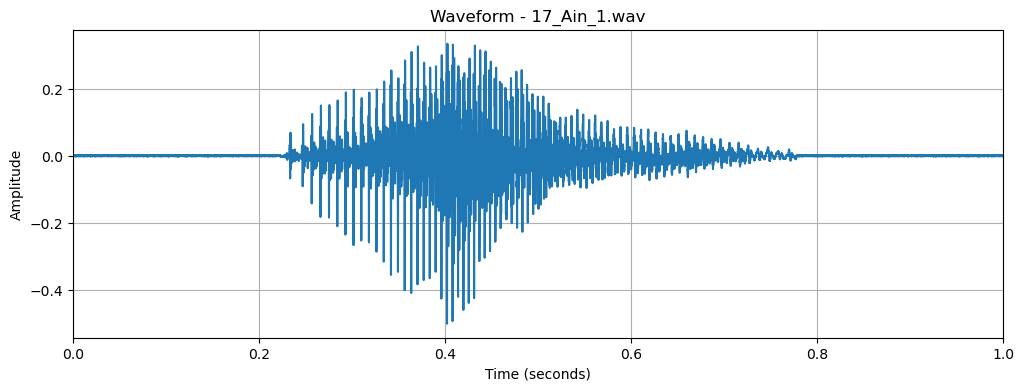

Sample rate: 16000 Hz
Duration: 1.0 seconds
Maximum amplitude: 0.5010681


In [ ]:
# بنرسم شكل الإشارة الصوتية لعينة من الداتا
import matplotlib.pyplot as plt
import numpy as np
import wave


sample_file = next((DATA_DIR / "Ain").glob("*.wav"))

with wave.open(str(sample_file), "rb") as audio_file:
    sample_rate = audio_file.getframerate()
    n_frames = audio_file.getnframes()
    sample_width = audio_file.getsampwidth()
    frames = audio_file.readframes(n_frames)

if sample_width == 2:
    audio = np.frombuffer(frames, dtype="<i2").astype(np.float32) / 32768.0
elif sample_width == 4:
    audio = np.frombuffer(frames, dtype="<i4").astype(np.float32) / 2147483648.0
elif sample_width == 1:
    audio = (np.frombuffer(frames, dtype=np.uint8).astype(np.float32) - 128) / 128.0
else:
    raise ValueError(f"Unsupported sample width: {sample_width}")

time = np.arange(len(audio)) / sample_rate

plt.figure(figsize=(12, 4))
plt.plot(time, audio)
plt.title(f"Waveform - {sample_file.name}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.xlim(0, len(audio) / sample_rate)
plt.grid(True)
plt.show()

print("Sample rate:", sample_rate, "Hz")
print("Duration:", len(audio) / sample_rate, "seconds")
print("Maximum amplitude:", np.max(np.abs(audio)))


In [17]:
%pip install librosa

  Using cached librosa-1.0.0-py3-none-any.whl.metadata (6.7 kB)
  Using cached decorator-5.3.1-py3-none-any.whl.metadata (3.9 kB)
  Using cached soundfile-0.14.0-py2.py3-none-win_amd64.whl.metadata (18 kB)
  Using cached pooch-1.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached soxr-1.1.0-cp312-abi3-win_amd64.whl.metadata (5.8 kB)
  Using cached msgpack-1.2.3-cp312-cp312-win_amd64.whl.metadata (8.5 kB)
Using cached librosa-1.0.0-py3-none-any.whl (294 kB)
Using cached decorator-5.3.1-py3-none-any.whl (10 kB)
Using cached msgpack-1.2.3-cp312-cp312-win_amd64.whl (76 kB)
Using cached pooch-1.9.0-py3-none-any.whl (67 kB)
Using cached soundfile-0.14.0-py2.py3-none-win_amd64.whl (1.0 MB)
Using cached soxr-1.1.0-cp312-abi3-win_amd64.whl (174 kB)
  Attempting uninstall: msgpack
    Found existing installation: msgpack 1.0.3
    Uninstalling msgpack-1.0.3:
      Successfully uninstalled msgpack-1.0.3
  Attempting uninstall: decorator
    Found existing installation: decorator 5.1.1
    Uninst

In [18]:
import librosa
print("Librosa version:", librosa.__version__)

Librosa version: 1.0.0


el code da test lel function ba3d ma katbnaha fe data_prep.py

In [23]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))

from data_prep import load_audio

test_file = next((DATA_DIR / "Ain").glob("*.wav"))

audio, sample_rate = load_audio(str(test_file))

print("File:", test_file.name)
print("Audio shape:", audio.shape)
print("Sample rate:", sample_rate)
print("Duration:", len(audio) / sample_rate, "seconds")
print("Audio dtype:", audio.dtype)

File: 17_Ain_1.wav
Audio shape: (16000,)
Sample rate: 16000
Duration: 1.0 seconds
Audio dtype: float32


In [28]:
from data_prep import get_splits

train_df, val_df, test_df = get_splits()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nTrain columns:", train_df.columns.tolist())
print("Train labels:", train_df["label"].nunique())

Train: (1004, 2)
Validation: (215, 2)
Test: (216, 2)

Train columns: ['file_path', 'label']
Train labels: 28


In [27]:
import importlib
import data_prep

importlib.reload(data_prep)

print(hasattr(data_prep, "get_splits"))

True


In [29]:
from pathlib import Path

processed_dir = Path("../data/processed")

for filename in ["metadata.csv", "train.csv", "val.csv", "test.csv"]:
    file_path = processed_dir / filename
    print(filename, "Exists:", file_path.exists())

metadata.csv Exists: True
train.csv Exists: True
val.csv Exists: True
test.csv Exists: True


In [30]:
total = len(train_df) + len(val_df) + len(test_df)

print(f"Train: {len(train_df) / total:.1%}")
print(f"Validation: {len(val_df) / total:.1%}")
print(f"Test: {len(test_df) / total:.1%}")
print(f"Total files: {total}")

Train: 70.0%
Validation: 15.0%
Test: 15.1%
Total files: 1435


In [31]:
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}")
    print("Number of classes:", df["label"].nunique())
    print("Missing values:", df[["file_path", "label"]].isna().sum().sum())
    print("Duplicate file paths:", df["file_path"].duplicated().sum())


Train
Number of classes: 28
Missing values: 0
Duplicate file paths: 0

Validation
Number of classes: 28
Missing values: 0
Duplicate file paths: 0

Test
Number of classes: 28
Missing values: 0
Duplicate file paths: 0


In [32]:
train_paths = set(train_df["file_path"])
val_paths = set(val_df["file_path"])
test_paths = set(test_df["file_path"])

print("Train ∩ Validation:", len(train_paths & val_paths))
print("Train ∩ Test:", len(train_paths & test_paths))
print("Validation ∩ Test:", len(val_paths & test_paths))

print("Total unique files:", len(train_paths | val_paths | test_paths))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0
Total unique files: 1435
